# Инциденты SRE: EDA и проверки качества

Лабораторная работа 5. Плотников Максим Александрович, магистратура, 3 семестр.

Разведочный анализ синтетического набора инцидентов из лабораторной 4: 6 000 карточек
телеком-оператора, три метки (критичность, сервис, корневая причина). Ноутбук проверяет
предположения, от которых зависят подготовка признаков, разделение выборок и оценка моделей.

Что внутри:

- восемь вопросов анализа, у каждого — решение, которое зависит от ответа;
- таблица из 19 проверок качества;
- восемь визуализаций с единицей счёта, выборкой и интерпретацией;
- просмотр типичных и проблемных карточек;
- проверка proxy-признаков и пересечений между выборками;
- обновление Data Card до версии 1.1.

Как воспроизвести. Данные в репозиторий не коммитятся, они пересобираются из seed:

```bash
python src/generate_incidents.py --count 6000
python src/prepare_dataset.py
python src/split_dataset.py
python src/eda_incidents.py
```

Последняя команда печатает таблицу проверок и рисует графики в `docs/lab5/figures`.
Ноутбук вызывает те же функции из `src/eda_incidents.py`, поэтому считает ровно то же самое.
В Colab первая ячейка клонирует репозиторий и прогоняет пайплайн, если файлов данных нет.

## 1. Вопросы анализа

Вопрос нужен, только если ответ меняет действие. Восемь вопросов ниже задают восемь графиков
и четыре решения по данным.

| № | Вопрос | От чего зависит ответ |
|---|---|---|
| 1 | Совпадает ли очищенный набор с зафиксированным объёмом и однозначна ли причина каждого исключения? | фиксируем версию 1.1 или пересобираем набор заново |
| 2 | Хватает ли записей на каждый класс критичности, сервиса и причины в каждой выборке? | считаем F1-macro и recall P1 по всем классам или только по устойчивым; нужна ли кросс-валидация |
| 3 | Не расходятся ли объёмы и метки между выборками, кроме известных исключений? | доверяем групповому разделению или пересобираем split |
| 4 | Где дубликаты: точные, почти-дубликаты одного шаблона и соседние карточки одного события? | нужна ли дополнительная дедупликация и что исключать из оценки поиска похожих |
| 5 | Насколько словарь train переносится на validation и test? | какие признаки брать: слова, n-граммы, символы; каких метрик ждать в ЛР 6 |
| 6 | Подсказывают ли служебные поля метку? | список полей, которые попадают в модель и в API |
| 7 | Есть ли сезонность и пропуски по времени? | нужен ли split по времени вместо группового |
| 8 | Что видно в проблемных карточках при просмотре? | правила фильтра для API и для индекса поиска похожих |

## 2. Данные и воспроизводимость

Ячейка ниже находит корень репозитория. Локально это папка на уровень выше `notebooks/`,
в Colab при пустом каталоге репозиторий клонируется с GitHub. Если файлов данных нет,
пайплайн отрабатывает три скрипта; генератор детерминированный, seed 20261123.

In [1]:
import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/aldentecoffe/Triage-Assistant.git"

ROOT = Path.cwd()
if not (ROOT / "src" / "eda_incidents.py").exists():
    ROOT = ROOT.parent
if not (ROOT / "src" / "eda_incidents.py").exists():
    REPO_DIR = Path.cwd() / "Triage-Assistant"
    if not (REPO_DIR / "src" / "eda_incidents.py").exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, str(REPO_DIR)], check=True)
    ROOT = REPO_DIR

os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))
print("Каталог репозитория:", ROOT.name)

PIPELINE = ("src/generate_incidents.py", "src/prepare_dataset.py", "src/split_dataset.py")
if not (ROOT / "data" / "raw" / "incidents_raw_v1.0.csv").exists():
    for script in PIPELINE:
        subprocess.run([sys.executable, script], check=True)

import pandas as pd
from IPython.display import Image, display

from eda_incidents import (
    combined,
    lexical_overlap,
    load_frames,
    plot_cleaning_funnel,
    plot_lexical_overlap,
    plot_proxies,
    plot_service_cause,
    plot_split_composition,
    plot_templates,
    plot_text_length,
    plot_time,
    proxy_table,
    ru,
    run_checks,
    template_key,
)

FIGURES = ROOT / "docs" / "lab5" / "figures"
pd.set_option("display.max_colwidth", 120)

Каталог репозитория: project


In [2]:
frames = load_frames(ROOT)
raw, clean = frames["raw"], frames["clean"]
frame = combined(frames)

print(f"сырой набор: {len(raw)} записей, {raw.shape[1]} столбцов")
print(f"очищенный набор: {len(clean)} записей")
print(f"журнал исключений: {len(frames['log'])} записей")
print(f"событий: {frame['event_id'].nunique()}, сценариев: {frame['scenario_id'].nunique()}")
print(f"сервисов: {frame['service'].nunique()}, причин: {frame['root_cause'].nunique()}")

by_split = pd.DataFrame(
    {
        split: {
            "карточек": len(frames[split]),
            "сценариев": frames[split]["scenario_id"].nunique(),
            "событий": frames[split]["event_id"].nunique(),
            "сервисов": frames[split]["service"].nunique(),
            "причин": frames[split]["root_cause"].nunique(),
        }
        for split in ("train", "validation", "test")
    }
).T
display(by_split)

severity = (
    frame["severity"].value_counts().rename("карточек").to_frame()
    .assign(доля=lambda table: (table["карточек"] / len(frame) * 100).round(1))
)
display(severity)

сырой набор: 6008 записей, 20 столбцов
очищенный набор: 6000 записей
журнал исключений: 8 записей
событий: 4110, сценариев: 28
сервисов: 7, причин: 6


,карточек,сценариев,событий,сервисов,причин
train,3600,14,2494,7,6
validation,1200,7,795,7,5
test,1200,7,821,7,6


,карточек,доля
P3,3031,50.5
P2,1678,28.0
P4,875,14.6
P1,416,6.9


Профиль совпадает с Data Card версии 1.0: 6 008 сырых карточек, 8 исключённых, 6 000 в работе,
20 столбцов, 28 сценариев и 4 110 событий. Классы критичности смещены к P3 (чуть больше половины),
P1 — 6,9 %. Доли сервисов почти равные, по 14,3 %, это удобство учебного набора, а не свойство
реального потока.

## 3. Проверки качества

19 проверок собраны в одном месте, в `src/eda_incidents.py`. Скрипт пишет их в
`docs/lab5/quality_checks.csv`, поэтому таблица в ноутбуке и в репозитории не расходятся.
Статусы: `ок` — проверка пройдена, `внимание` — известное ограничение или риск, который
не мешает работе, `проблема` — данные нельзя использовать до исправления.

In [3]:
results, groups = run_checks(frames)
checks = pd.DataFrame(results).rename(
    columns={"check": "Проверка", "value": "Факт", "decision": "Решение", "status": "Статус"}
)
checks["Статус"] = checks["Статус"].map({"ok": "ок", "warn": "внимание", "fail": "проблема"})
display(checks)
print(checks["Статус"].value_counts().to_string())

,Проверка,Факт,Решение,Статус
0,Объём raw и clean,"6008 и 6000 записей, исключено 8",ожидание 6000; набор версии 1.0 воспроизводится,ок
1,Состав выборок и clean,"train 3600, validation 1200, test 1200; записей clean без выборки: 0, лишних в выборках: 0, повторов между выборками: 0",выборки собраны из этого очищенного набора,ок
2,Схема,"20 столбцов, расхождений с REQUIRED_COLUMNS: 0",схема v1.0 без изменений,ок
3,Пустые обязательные поля,0 пустых значений в очищенном наборе,заполнено полностью,ок
4,Уникальность ключей и хешей,"повторов incident_id: 0, affected_ci: 0, пустых affected_ci: 0, расхождений text_hash: 0",ключи и хеши пригодны для группировки,ок
5,Точные дубли текста,0 повторов text_hash в очищенном наборе,дубликаты снимаются очисткой,ок
6,Допустимые значения меток,нарушений: 0,словари API повторяют значения схемы,ок
7,Журнал исключений,1. rights_unknown: 3; 2. empty_or_short_description: 2; 3. duplicate_text: 3,каждая запись получает одну причину по порядку проверок,ок
8,Пересечение групп между выборками,0 нарушений,"групповой split подтверждён: сценарий, событие и текст не пересекаются",ок
9,Каскады в одной выборке,"пар: 4, событий: 12, разъехавшихся пар: 0",каскад нельзя разделять: карточки описывают одно происшествие,ок


ок          15
внимание     4


Ни одна проверка не дала `проблему`: объём, состав выборок, схема, ключи, хеши, допустимые
значения и журнал исключений в порядке. Четыре предупреждения, но причин три. В validation нет
категории `network` (два её сценария попали в train и test), поэтому метрику по этой причине
на validation не считаем; об этом говорят две строки сразу — покрытие меток и поддержка
классов. Почти все карточки имеют почти-дубликат того же шаблона: это следствие генератора,
именно поэтому разделение групповое по сценарию. Номер CI выдаётся по порядку генерации,
поэтому его дециль связан с сервисом на 0,62: поле остаётся журнальным атрибутом и в признаки
не попадает.

Дальше каждое решение подкреплено графиком. У каждого графика указаны единица счёта и выборка:
без этого столбик «6 000» легко прочитать как шесть тысяч независимых наблюдений.

## 4. Визуализации

### 4.1 Очистка набора

**Единица счёта:** карточка инцидента. **Выборка:** сырой набор 6 008 карточек и журнал
исключений. **Что видно:** после проверки прав остаётся 6 005, после проверки описания —
6 003, после удаления точных дублей — 6 000. Три исключения по правам, два по пустому
описанию, три дубликата.

**Решение:** объём и причины исключений воспроизводятся, данные остаются версией 1.0, а
документ получает версию 1.1. Те же три фильтра обязаны стоять в API: запись без
подтверждённого допуска или с пустым описанием не должна попадать в выдачу.

Порядок проверок важен: карточки без прав совпадают по тексту с разрешёнными, а два пустых
описания совпадают друг с другом по хешу. Если проверять дубликаты первыми, отчёт показал бы
семь дубликатов и ноль записей без допуска.

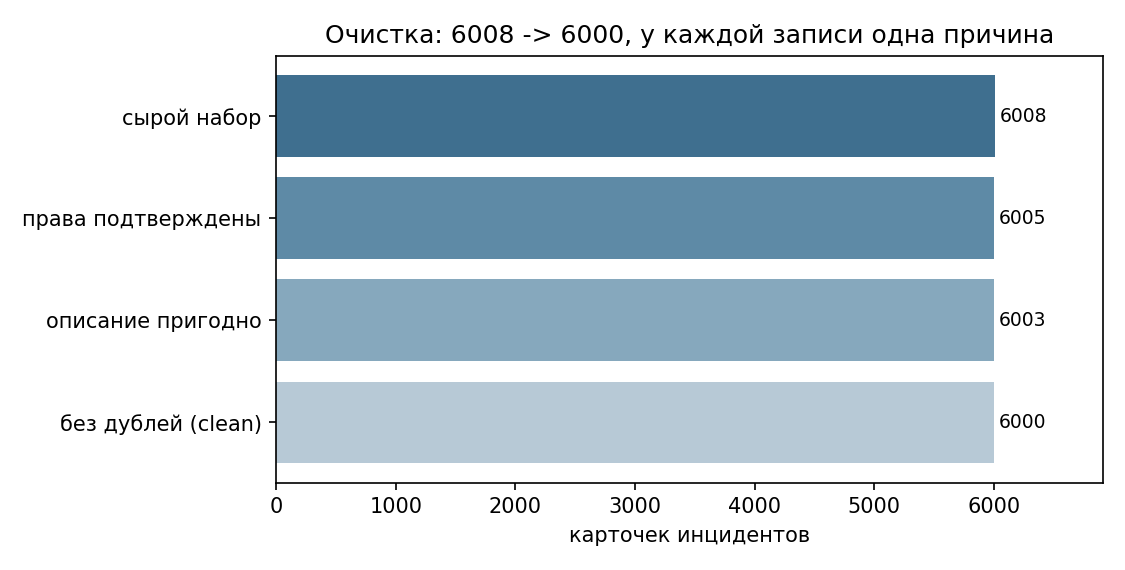

In [4]:
path = plot_cleaning_funnel(frames, FIGURES)
display(Image(filename=str(path)))

### 4.2 Состав выборок и критичность

**Единица счёта:** карточка. **Выборка:** 6 000 очищенных карточек, разбитые на train 3 600,
validation 1 200 и test 1 200. **Что видно:** доли P1 расходятся между выборками — 7,1 %,
4,4 % и 8,9 %. Это не ошибка разбиения: критичность разыгрывается на событие, а набор сценариев
в выборках разный.

**Решение:** P1 остаётся отдельной метрикой (recall), но сравнивать выборки по абсолютной доле
P1 нельзя. Эффективный размер выборки — 14, 7 и 7 сценариев, а не 3 600 и 1 200 карточек,
поэтому доверительный интервал считается блочным бутстрэпом по сценариям.

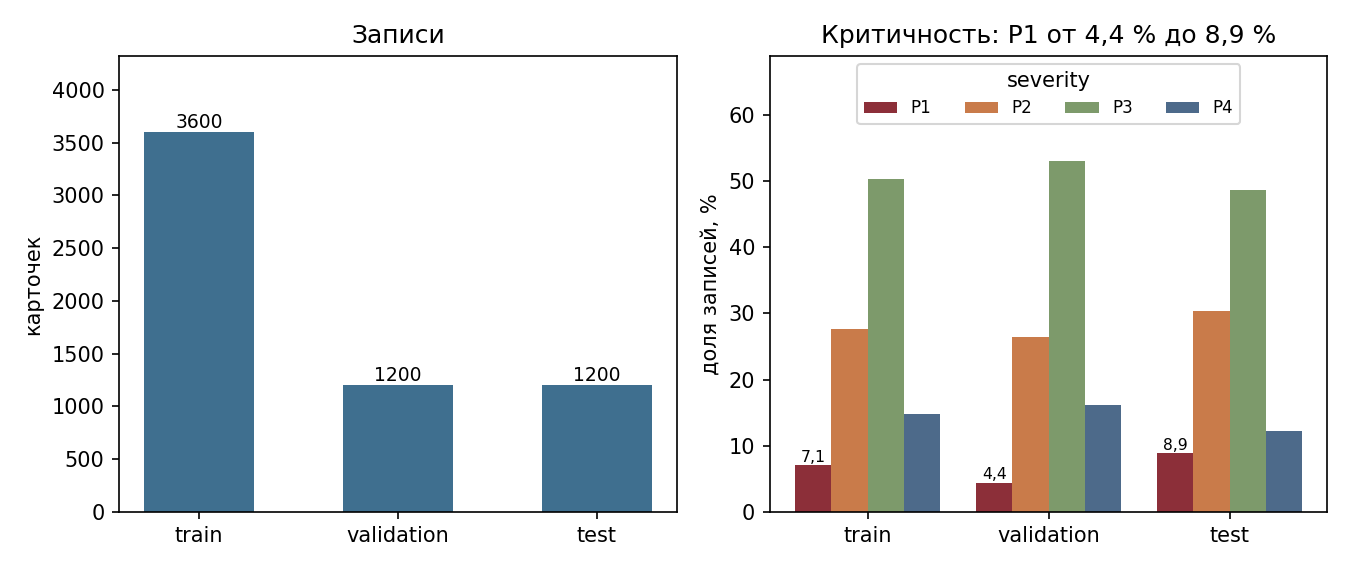

In [5]:
path = plot_split_composition(frames, FIGURES)
display(Image(filename=str(path)))

### 4.3 Сервис и корневая причина

**Единица счёта:** карточка. **Выборка:** очищенный набор, таблица сопряжённости сервис ×
причина. **Что видно:** заполнено 25 ячеек из 42, по 171-430 карточек в ячейке. Это цена
таксономии из 28 сценариев: каждая пара «сервис, причина» описана одним-двумя сценариями.

**Решение:** F1-macro по сервису и причине считается по классам целиком, а не по ячейкам;
редкие пары в отчёте приводятся с числом карточек. Расширять таксономию на этом объёме
нельзя по той же причине, что записана в схеме: при десяти категориях причин на 6 000
записей редкие получают меньше 300 примеров, и F1 по ним превращается в шум.

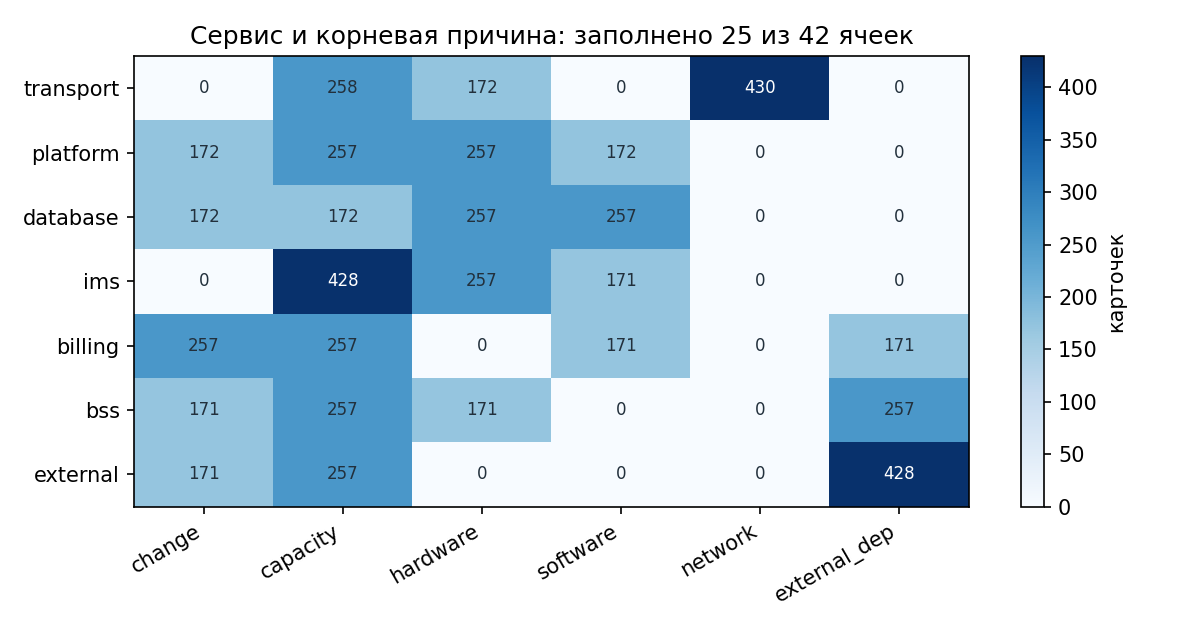

In [6]:
path = plot_service_cause(clean, FIGURES)
display(Image(filename=str(path)))

### 4.4 Длина описания

**Единица счёта:** карточка. **Выборка:** очищенный набор, отдельно русские (4 778) и
английские (1 222) карточки. **Что видно:** длина от 14 до 35 токенов, медиана 22.
Английские тексты длиннее на 4 токена: структура шаблона та же, но формулировка длиннее.
Выбросов по длине нет — ни значений ниже порога, ни текстов длиннее 35 токенов.

**Решение:** усечение не нужно, description целиком уходит в TF-IDF. Порог в 5 токенов
на этом наборе ничего не отсекает (в очищенном наборе таких карточек нет), но остаётся
в фильтре API: реальная выгрузка придёт с пустыми описаниями.

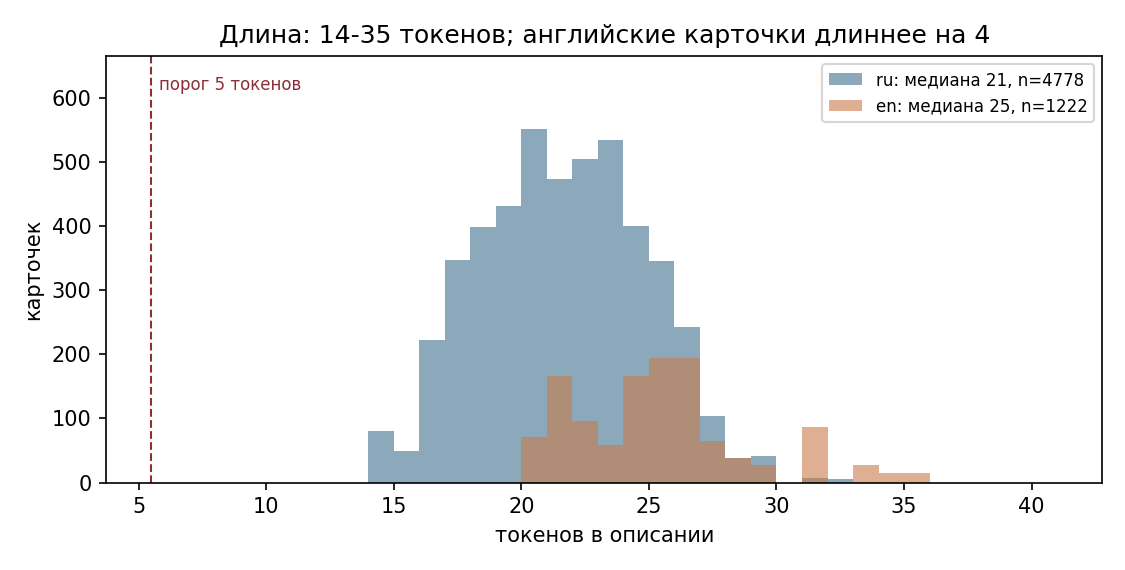

In [7]:
path = plot_text_length(clean, FIGURES)
display(Image(filename=str(path)))

### 4.5 Перенос словаря

**Единица счёта:** слово (токен) и карточка. **Выборка:** словарь train против validation
и test. **Что видно:** в test 62,7 % токенов встречаются в train, в validation — 60,1 %.
Полное покрытие на 80 % и выше есть лишь у 2,8 % карточек validation и ни у одной карточки test.
По сервисам разброс небольшой: от 54 % у transport до 70 % у bss.

**Решение:** общий словарь у выборок есть, знакомых формулировок нет. Модель сможет переносить
отдельные слова и каркас фразы, но не готовые шаблоны, поэтому в ЛР 6 базовый вариант —
TF-IDF по словам и символьным n-граммам плюс линейная модель. Ждать целевых 0,75 и 0,80
с первого прогона оснований нет; это проверяется моделью, а не объявляется заранее.

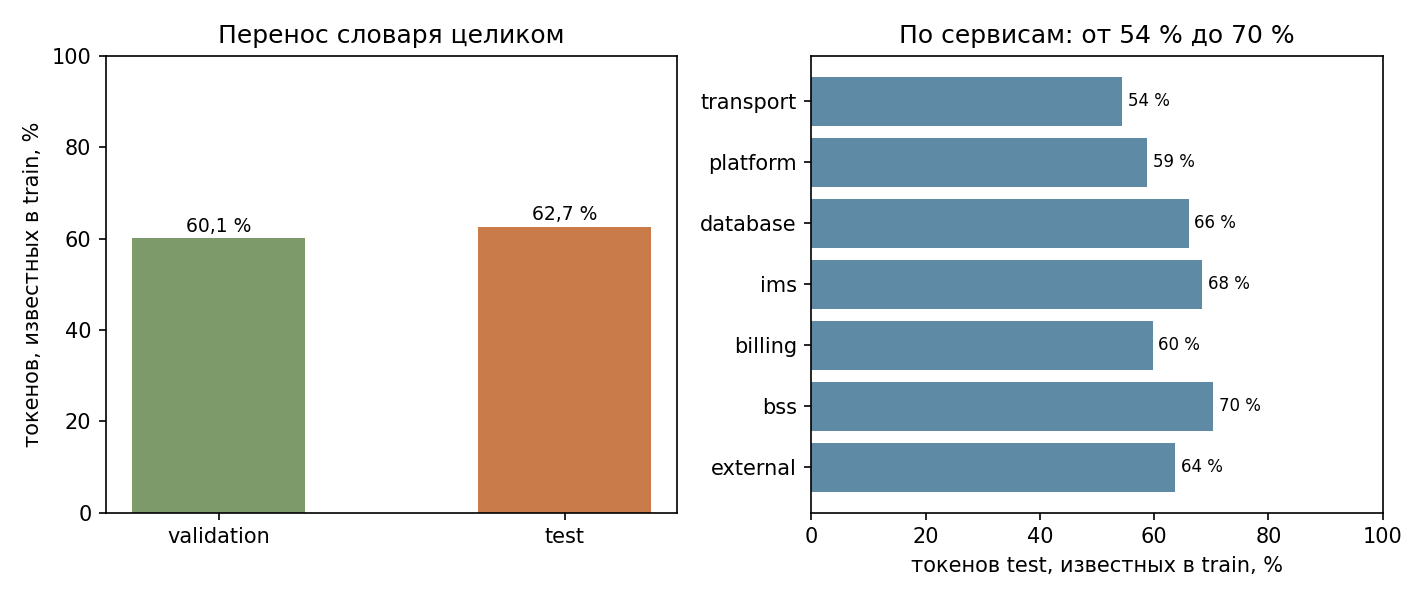

In [8]:
path = plot_lexical_overlap(frames, FIGURES)
display(Image(filename=str(path)))

### 4.6 Шаблоны и почти-дубликаты

**Единица счёта:** шаблон — текст, в котором числа, номера CI и имена узлов заменены
заглушками. **Выборка:** очищенный набор. **Что видно:** 6 000 карточек сводятся к 749
шаблонам. Серий из двух и больше карточек — 737, они покрывают 5 988 карточек, то есть 99,8 %.
Ни один шаблон не встречается в двух выборках, ни один не обслуживает два сценария.

**Решение:** проверки по `text_hash` недостаточно, она видит только точные копии. Утечку
закрывает группировка по сценарию: при случайном разделении почти у каждой карточки test был бы
почти-двойник в train, и метрика показала бы запоминание шаблона. Оценку поиска похожих
придётся считать отдельно и исключать карточки того же события.

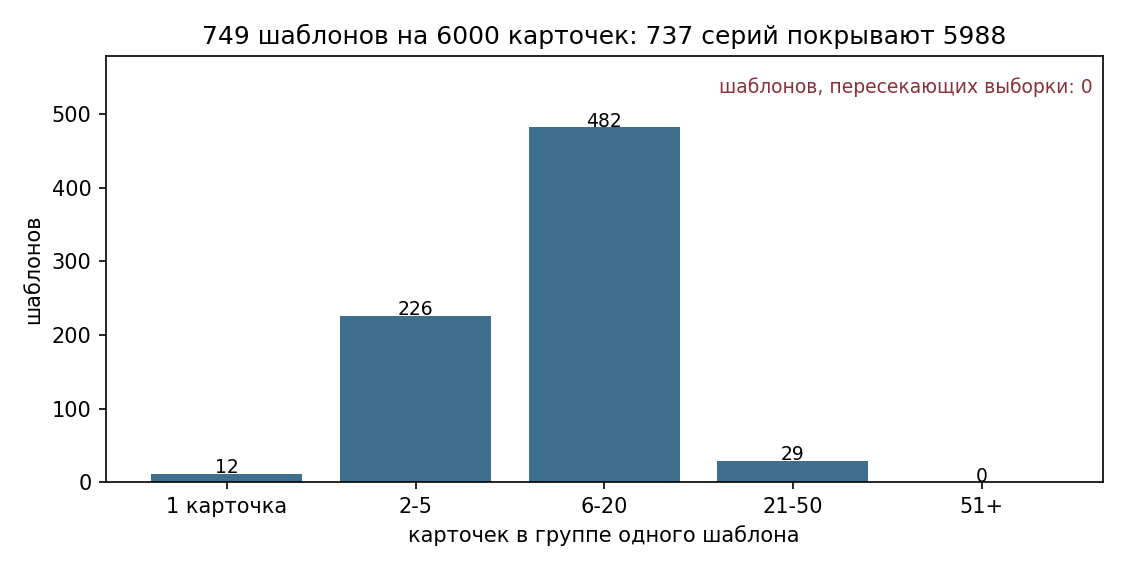

In [9]:
path = plot_templates(groups, clean, FIGURES)
display(Image(filename=str(path)))

### 4.7 Служебные поля как proxy-признаки

**Единица счёта:** карточка. **Выборка:** очищенный набор. **Что видно:** Cramer's V для
`source_system`, `region`, `language` и кода региона из имени узла не превышает 0,04 по всем
трём меткам. Другая картина у двух идентификаторов: дециль номера `affected_ci` связан с
сервисом на 0,62 и с причиной на 0,51, а `scenario_id` — на 1,00.

**Решение:** в модель идёт только `description`. `title` повторяет слова описания у 100 %
карточек, `scenario_id` и `event_id` — служебные ключи. Номер CI выглядит безобидно, но выдаётся
по порядку генерации, и диапазоны номеров группируются по сценарию; как признак он тоже
не используется. В API `source_system` и `region` можно принять, на ответ они не влияют.

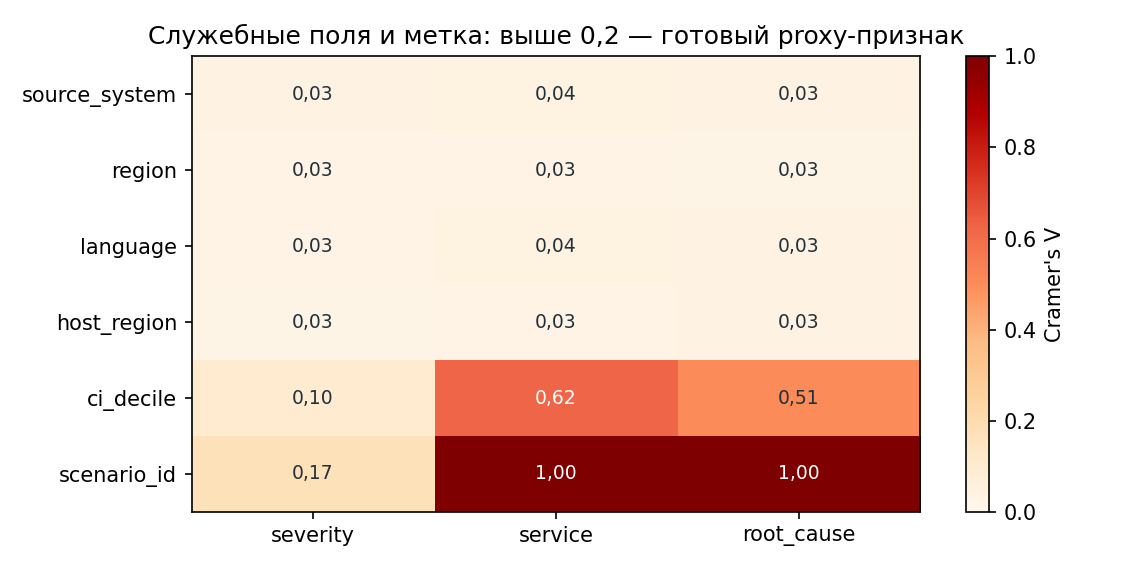

Cramer's V для scenario_id:


,severity,service,root_cause
field,,,
scenario_id,0.17,1.0,1.0


In [10]:
path = plot_proxies(proxy_table(clean), FIGURES)
display(Image(filename=str(path)))
print("Cramer's V для scenario_id:")
display(proxy_table(clean).set_index("field").loc[["scenario_id"]])

### 4.8 Покрытие по времени

**Единица счёта:** карточка в календарной неделе. **Выборка:** очищенный набор,
2026-08-01 - 2026-11-19. **Что видно:** 17 недель с данными и ни одной пустой; первая и
последняя недели неполные, в среднем 353 карточки в неделю. Сезонных пиков на графике нет.

**Решение:** разделение по времени не даёт выигрыша и не нужно: набор покрывает четыре месяца
равномерно, а групповой split по сценариям строже случайного. `created_at` в признаки
не входит.

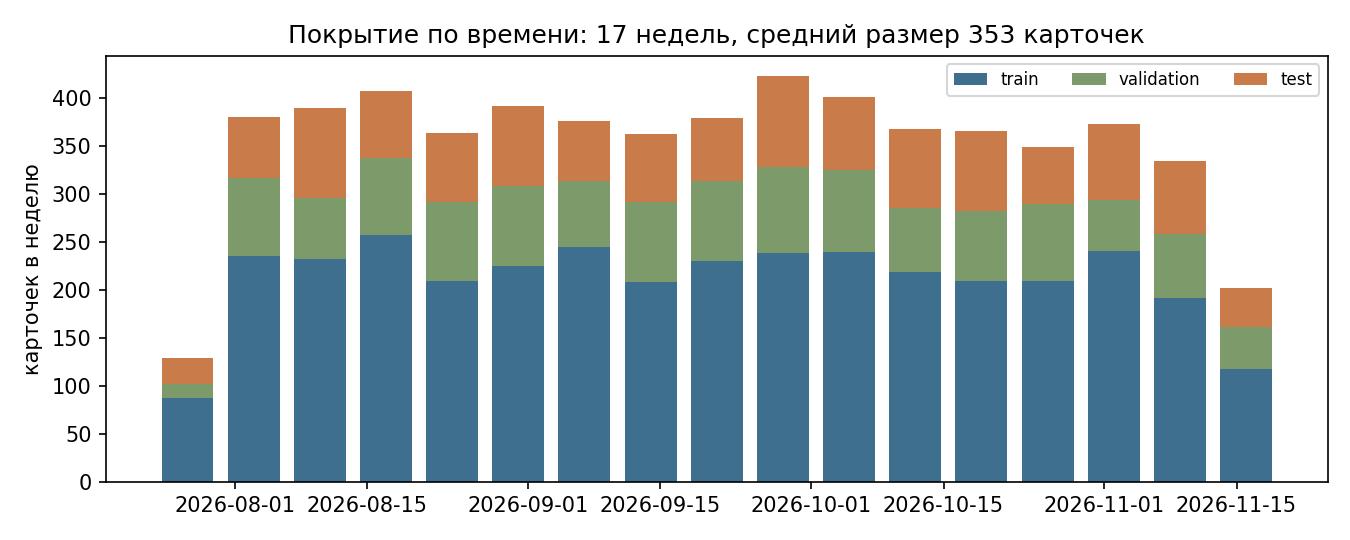

In [11]:
path = plot_time(frame, FIGURES)
display(Image(filename=str(path)))

## 5. Просмотр типичных и проблемных карточек

Числовая таблица не показывает, что текст обрезан или что две карточки — одна и та же запись.
Ниже семь случаев: две типичные карточки одного сценария на разных языках, точный дубль,
карточка без допуска, пустое описание, каскад и почти-дубликат одного шаблона.

In [12]:
def short(text, limit=105):
    value = " ".join(str(text).split())
    return value if len(value) <= limit else value[:limit] + "..."


def duplicate_groups():
    duplicated = raw[raw["text_hash"].duplicated(keep=False)]
    return [part for _, part in duplicated.groupby("text_hash")]


def find_cascade_event():
    sizes = frame.groupby("event_id")["service"].nunique()
    return frame[frame["event_id"] == sizes[sizes > 1].index[0]]


template_table = clean.assign(template=clean["description"].map(template_key))
biggest = template_table["template"].value_counts().index[0]
siblings = template_table[template_table["template"] == biggest].head(2)
typical_ru = clean[(clean["scenario_id"] == "SC-TRN-01") & (clean["language"] == "ru")].iloc[0]
typical_en = clean[(clean["scenario_id"] == "SC-TRN-01") & (clean["language"] == "en")].iloc[0]

allowed_pair = next(part for part in duplicate_groups() if part["rights_status"].eq("demo_allowed").all())
unknown_row = raw[raw["rights_status"] == "unknown"].iloc[0]
unknown_twin = raw[
    (raw["text_hash"] == unknown_row["text_hash"])
    & (raw["incident_id"] != unknown_row["incident_id"])
].iloc[0]

rows = []


def add(kind, ids, what, decision):
    rows.append({"пример": kind, "записи": ids, "что видно": what, "решение": decision})


add("типичная карточка, ru", typical_ru["incident_id"], short(typical_ru["description"]),
    "симптом, значение метрики, последствие и CI — годится как вход модели")
add("та же формулировка, en", typical_en["incident_id"], short(typical_en["description"]),
    "язык меняется, структура нет: один векторизатор на оба")

add("точный дубль", ", ".join(allowed_pair["incident_id"]), short(allowed_pair["description"].iloc[0]),
    "один text_hash: вторая карточка снимается очисткой")
add("права не подтверждены", unknown_row["incident_id"], short(unknown_row["description"]),
    f"текст совпадает с {unknown_twin['incident_id']}, но допуска нет: "
    "журнал затирает текст, в clean записи нет")

empty = raw[raw["description"].str.strip() == ""].iloc[-1]
add("пустое описание", empty["incident_id"],
    f"{empty['description']!r}, значащих символов: {len(empty['description'].strip())}",
    "нет текста — нет модели; фильтр длины обязателен в API")

cascade = find_cascade_event()
add("каскад", ", ".join(cascade["incident_id"]),
    short(cascade["description"].iloc[0]),
    f"одно событие {cascade['event_id'].iloc[0]}, сервисы {', '.join(cascade['service'].unique())}: "
    "из выдачи похожих соседей по событию исключаем")

add("почти-дубликат", ", ".join(siblings["incident_id"]),
    short(siblings["description"].iloc[1]),
    "один шаблон, разные значения метрики и CI: text_hash их не видит")

review = pd.DataFrame(rows)
display(review)
sizes = frame.groupby("event_id").size()
with_siblings = int(sizes[sizes > 1].sum())
print("карточек с соседом по событию:", with_siblings, "из", len(frame))
print("доля:", ru(with_siblings / len(frame) * 100) + " %")
print("карточек сверх одной на событие:", len(frame) - frame["event_id"].nunique())

,пример,записи,что видно,решение
0,"типичная карточка, ru",I000024,Падает BGP-сессия с пирингом; BGP_Peers_Established 1 шт. Часть клиентских префиксов анонсируется через р...,"симптом, значение метрики, последствие и CI — годится как вход модели"
1,"та же формулировка, en",I000120,BGP session with the upstream peer keeps flapping. route_withdrawals is 57/min against threshold 50/min. ...,"язык меняется, структура нет: один векторизатор на оба"
2,точный дубль,"I000143, I004109",Коммутатор теряет FIB-записи под нагрузкой на host-msk194. prefix_count держится 3 860 555 шт при пороге ...,один text_hash: вторая карточка снимается очисткой
3,права не подтверждены,I001509,Таблица маршрутизации упирается в лимит FIB на host-krd183. prefix_count держится 4 066 078 шт при пороге...,"текст совпадает с I001196, но допуска нет: журнал затирает текст, в clean записи нет"
4,пустое описание,I005014,"' ', значащих символов: 0",нет текста — нет модели; фильтр длины обязателен в API
5,каскад,"I000019, I001554, I005100",Обработчик записей не успевает за потоком на host-ekb194. cdr_queue_depth держится 304 130 шт при пороге ...,"одно событие E000001, сервисы billing, transport: из выдачи похожих соседей по событию исключаем"
6,почти-дубликат,"I000050, I000079",Double charges appear after the rating rules release. double_charge_events is 330/h against threshold 300...,"один шаблон, разные значения метрики и CI: text_hash их не видит"


карточек с соседом по событию: 3125 из 6000
доля: 52,1 %
карточек сверх одной на событие: 1890


Два вывода из просмотра. Дубликаты и пустые описания — дефекты данных, а не модели: они
снимаются до обучения, поэтому в чистых метриках их влияние не видно. Каскад — обратный случай:
обе карточки валидны, но описывают одно происшествие. Если поиск похожих вернёт соседа по
событию, инженер получит ссылку на ту же аварию под другим сервисом, а оценка такого поиска
будет завышена. Поэтому в оценке top-3 карточки одного `event_id` исключаются.

## 6. Утечки и proxy: что проверено

Проверка утечек в этом наборе сводится к трём каналам.

1. **Сценарий.** Текст одного сценария собран из двух-трёх формулировок и отличается
   значением метрики и номером CI. Проверка: ни один сценарий не встречается в двух выборках,
   каскадные пары не разъехались, шаблоны не пересекают выборки.
2. **Событие.** Карточки одного происшествия почти дословно совпадают и делят критичность.
   Проверка: 4 110 событий, ни одного противоречия по severity, разброс времени внутри
   события не больше 30 минут.
3. **Служебные поля.** `scenario_id` связан с метками на 1,00, но в признаки не входит.
   `source_system`, `region`, `language` и код региона в имени узла дают V не выше 0,04.
   Номер `affected_ci` выдан счётчиком в порядке генерации: его дециль связан с сервисом
   на 0,62 и с причиной на 0,51, поэтому поле тоже остаётся вне признаков.

Имена узлов содержат код города, но город разыгрывается независимо от метки: V не выше 0,04.

In [13]:
print("Групп в нескольких выборках:")
for key in ("scenario_id", "event_id", "text_hash"):
    crossing = int((frame.groupby(key)["split"].nunique() > 1).sum())
    print(f"  {key}: {crossing}")

print("Шаблонов в нескольких выборках:", int((groups["splits"] > 1).sum()))

for split in ("validation", "test"):
    share, covered = lexical_overlap(frames["train"], frames[split])
    print(f"{split}: известных токенов {ru(share * 100)} %, карточек с покрытием 80 %+ {ru(covered * 100)} %")

print("Повторов text_hash в clean:", int(clean["text_hash"].duplicated().sum()))
print("Событий с разными severity:", int((frame.groupby("event_id")["severity"].nunique() > 1).sum()))

Групп в нескольких выборках:
  scenario_id: 0
  event_id: 0
  text_hash: 0
Шаблонов в нескольких выборках: 0
validation: известных токенов 60,1 %, карточек с покрытием 80 %+ 2,8 %
test: известных токенов 62,7 %, карточек с покрытием 80 %+ 0,0 %
Повторов text_hash в clean: 0
Событий с разными severity: 0


## 7. Что меняется в плане

Проверки не нашли дефектов, которые требуют пересборки набора, но меняют четыре решения.

**Данные.** Остаётся версия 1.0 с тем же объёмом 6 000 карточек; Data Card повышается
до 1.1 как документ, потому что добавились проверки, графики и измеренный перенос.

**Признаки.** В модель идёт только `description`. `title` — сжатая копия описания,
`scenario_id` и `event_id` — служебные ключи, `affected_ci` упорядочен по генерации,
`source_system`, `region`, `language` и `created_at` сигнала не несут. API принимает часть
этих полей для журнала, но на ответ они не влияют.

**Метрики.** По каждой задаче F1-macro, для P1 отдельно recall. Доверительный интервал —
блочный бутстрэп по сценариям: в validation и test по семь сценариев. По категории `network`
метрика на validation не считается, вывод делается на кросс-валидации train. Поиск похожих
оценивается без карточек того же события.

**Ожидания ЛР 6.** Словарь общий на 60-63 %, полного покрытия текста почти нет, поэтому
первый baseline — TF-IDF по словам и символам с линейной моделью. Если F1-macro по сервису
окажется заметно ниже 0,80, сначала проверяются символьные n-граммы и лемматизация,
и только потом обсуждается смена модели. Целевые значения остаются целями, а не обещанием.

## 8. Data Card 1.1

Изменения относительно версии 1.0 записаны в
[docs/lab5/data_card_update.md](../docs/lab5/data_card_update.md). Коротко:

- объём не изменился: 6 008 сырых, 8 исключённых, 6 000 очищенных карточек, версия набора 1.0;
- пройдено 19 проверок, четыре с пометкой «внимание»: в validation нет `network` (это видно
  сразу в покрытии меток и в поддержке классов), почти все карточки имеют почти-дубликат
  своего шаблона, номер CI упорядочен по генерации;
- измерен перенос словаря: 60,1 % токенов validation и 62,7 % токенов test известны train,
  полное покрытие текста — 2,8 % и 0 %;
- проверены proxy-каналы: обычные служебные поля дают V не выше 0,04, а `scenario_id` (1,00)
  и дециль `affected_ci` (0,62) подсказывают метку и потому в признаки не входят.

Артефакты: [таблица проверок](../docs/lab5/quality_review.md),
[как запустить](../docs/lab5/eda_run.md), графики в `docs/lab5/figures/`.

## 9. Самопроверка

Вопрос из методички: какая визуализация изменила бы решение, покажи она неожиданный результат.

Шаблоны. Если бы группы одного шаблона пересекали выборки, split пришлось бы пересобрать,
а все прошлые метрики аннулировать: модель училась бы на копиях. Проверка показывает ноль
пересечений, поэтому разделение остаётся.

Второй такой график — перенос словаря. При покрытии близком к нулю пришлось бы менять признаки
(символьные n-граммы, эмбеддинги) или признать, что на этих данных модель проверяет только
устойчивость пайплайна, а не качество триажа.